<a href="https://colab.research.google.com/github/Nazarchuk-Viktoriia/Python-Projects/blob/main/Exploratory_Data_Analysis_for_a_Sales_Company.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount("/content/drive")
%cd /content/drive/My Drive/Mate Academy/Python for Data Analytics/Final project

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/My Drive/Mate Academy/Python for Data Analytics/Final project


In [ ]:
events = pd.read_csv("events.csv")
countries = pd.read_csv("countries.csv")
products = pd.read_csv("products.csv")

# 1. Data overview

### Таблиця `events`

In [ ]:
events.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.0,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,1993.0,205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,4693.0,668.27,502.54
3,102230632,5/13/2017,6/13/2017,L,MNE,2455,Online,1171.0,109.28,35.84
4,103435266,8/11/2012,9/18/2012,H,SRB,1270,Offline,7648.0,47.45,31.79


In [ ]:
events.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1330 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1330 non-null   int64  
 1   Order Date      1330 non-null   object 
 2   Ship Date       1330 non-null   object 
 3   Order Priority  1330 non-null   object 
 4   Country Code    1248 non-null   object 
 5   Product ID      1330 non-null   int64  
 6   Sales Channel   1330 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1330 non-null   float64
 9   Unit Cost       1330 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 104.0+ KB


In [ ]:
print(events["Order Priority"].unique())

['M' 'C' 'L' 'H' ' C' 'M ']


In [ ]:
print(events["Sales Channel"].unique())

['Online' 'Offline' 'online']


**Загальна інформація:** 1330 рядків, 10 стовпців.

* **`Order ID`** — унікальний ідентифікатор замовлення.
* **`Order Date`** — дата оформлення замовлення **(потребує конвертації в datetime)**.
* **`Ship Date`** — дата відвантаження **(потребує конвертації в datetime)**.
* **`Order Priority`** — пріоритет виконання замовлення **(містить зайві пробіли)**.
* **`Country Code`** — код країни покупця **(82 пропуски)**.
* **`Product ID`** — ідентифікатор товару.
* **`Sales Channel`** — канал продажу **(містить однакове значення в різному регістрі)**.
* **`Units Sold`** — кількість проданих одиниць товару **(2 пропуски)**.
* **`Unit Price`** — роздрібна ціна за одиницю товару.
* **`Unit Cost`** — собівартість одиниці товару.

### Таблиця `countries`

In [ ]:
countries.head()

,name,alpha-2,alpha-3,region,sub-region
0,Afghanistan,AF,AFG,Asia,Southern Asia
1,Åland Islands,AX,ALA,Europe,Northern Europe
2,Albania,AL,ALB,Europe,Southern Europe
3,Algeria,DZ,DZA,Africa,Northern Africa
4,American Samoa,AS,ASM,Oceania,Polynesia


In [ ]:
countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     248 non-null    object
 2   alpha-3     249 non-null    object
 3   region      248 non-null    object
 4   sub-region  248 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


**Загальна інформація:** 249 рядків, 5 стовпців. Усі стовпці мають текстовий тип даних.

* **`name`** — назва країни.
* **`alpha-2`** — дволітерний код країни **(1 пропуск)**.
* **`alpha-3`** — трилітерний код країни.
* **`region`** — регіон **(1 пропуск)**.
* **`sub-region`** — субрегіон **(1 пропуск)**.

### Таблиця `products`

In [ ]:
products.head()

,id,item_type
0,2103,Cereal
1,7940,Household
2,2455,Clothes
3,1270,Beverages
4,8681,Office Supplies


In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


In [ ]:
products["id"].nunique()

12

**Загальна інформація:** 12 рядків, 2 стовпці.

* **`id`** — унікальний ідентифікатор товару.
* **`item_type`** — категорія товару.

### **Зв'язки між таблицями:**
Основна таблиця `events` поєднується:

* **З таблицею `products`:** поле `Product ID` (з `events`) відповідає полю `id` (з `products`).
* **З таблицею `countries`:** поле `Country Code` (з `events`) відповідає полю `alpha-3` (з `countries`).

# 2. Data cleaning

### Таблиця `events`

In [ ]:
print(events.isna().sum())

Order ID           0
Order Date         0
Ship Date          0
Order Priority     0
Country Code      82
Product ID         0
Sales Channel      0
Units Sold         2
Unit Price         0
Unit Cost          0
dtype: int64


In [ ]:
print(events.isna().sum() / events.shape[0] * 100)

Order ID          0.000000
Order Date        0.000000
Ship Date         0.000000
Order Priority    0.000000
Country Code      6.165414
Product ID        0.000000
Sales Channel     0.000000
Units Sold        0.150376
Unit Price        0.000000
Unit Cost         0.000000
dtype: float64


* **`Country Code`** містить 82 пропущених значення (6.17%). Це доволі помітна частка, і видаляти ці рядки не можна, оскільки ми втратимо інформацію про доходи з цих замовлень. Щоб врахувати їх при подальшому аналізі, заповнимо ці пропуски значенням `Unknown`. Ймовірні причини: клієнт не вказав країну під час оформлення, або система не змогла визначити її автоматично.

* **`Units Sold`** містить 2 пропущених значення. Їх частка мізерна (близько 0.15%), тому ці рядки можна безпечно видалити без впливу на загальну статистику. Ймовірна причина: помилка під час ручного внесення даних або системний збій під час оновлення бази.

In [ ]:
events["Country Code"] = events["Country Code"].fillna("Unknown")

In [ ]:
events["Country Code"].unique()

array(['NOR', 'SRB', 'Unknown', 'MNE', 'SVK', 'FRA', 'ESP', 'HRV', 'DEU',
       'ARM', 'GEO', 'GBR', 'SVN', 'ROU', 'POL', 'LUX', 'CYP', 'BEL',
       'LTU', 'RUS', 'MLT', 'UKR', 'CZE', 'PRT', 'BLR', 'EST', 'AUT',
       'MKD', 'SMR', 'NLD', 'CHE', 'HUN', 'LVA', 'BGR', 'ITA', 'IRL',
       'AND', 'LIE', 'FIN', 'ALB', 'SWE', 'BIH', 'DNK', 'MCO', 'ISL',
       'GRC'], dtype=object)

In [ ]:
events = events.dropna(subset=["Units Sold"])

In [ ]:
events.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1328 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Order ID        1328 non-null   int64  
 1   Order Date      1328 non-null   object 
 2   Ship Date       1328 non-null   object 
 3   Order Priority  1328 non-null   object 
 4   Country Code    1328 non-null   object 
 5   Product ID      1328 non-null   int64  
 6   Sales Channel   1328 non-null   object 
 7   Units Sold      1328 non-null   float64
 8   Unit Price      1328 non-null   float64
 9   Unit Cost       1328 non-null   float64
dtypes: float64(3), int64(2), object(5)
memory usage: 114.1+ KB


Після заповнення та видалення пропусків маємо **1328 рядків**.

In [ ]:
events["Ship Date"]=pd.to_datetime(events["Ship Date"])
events["Order Date"]=pd.to_datetime(events["Order Date"])
events.info()

<class 'pandas.core.frame.DataFrame'>
Index: 1328 entries, 0 to 1329
Data columns (total 10 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order ID        1328 non-null   int64         
 1   Order Date      1328 non-null   datetime64[ns]
 2   Ship Date       1328 non-null   datetime64[ns]
 3   Order Priority  1328 non-null   object        
 4   Country Code    1328 non-null   object        
 5   Product ID      1328 non-null   int64         
 6   Sales Channel   1328 non-null   object        
 7   Units Sold      1328 non-null   float64       
 8   Unit Price      1328 non-null   float64       
 9   Unit Cost       1328 non-null   float64       
dtypes: datetime64[ns](2), float64(3), int64(2), object(3)
memory usage: 114.1+ KB


Перетворили значення `Order Date`, `Ship Date` в тип datetime.

In [ ]:
print(events["Order Priority"].value_counts())

Order Priority
M     352
H     335
L     334
C     304
 C      2
M       1
Name: count, dtype: int64


In [ ]:
events["Order Priority"] = events["Order Priority"].str.strip()

In [ ]:
print(events["Order Priority"].value_counts())

Order Priority
M    353
H    335
L    334
C    306
Name: count, dtype: int64


In [ ]:
print(events["Sales Channel"].value_counts())

Sales Channel
Offline    665
Online     660
online       3
Name: count, dtype: int64


In [ ]:
events["Sales Channel"] = events["Sales Channel"].str.title()

In [ ]:
print(events["Sales Channel"].value_counts())

Sales Channel
Offline    665
Online     663
Name: count, dtype: int64


In [ ]:
duplicate_rows = events.duplicated()
print(duplicate_rows)
print(duplicate_rows.sum())


0       False
1       False
2       False
3       False
4       False
        ...  
1325    False
1326    False
1327    False
1328    False
1329    False
Length: 1328, dtype: bool
0


Дублікати виникли в колонці `Order Priority` через зайві пробіли, та в `Sales Channel` через розбіжність у великих/малих літерах.

In [ ]:
events.describe()

,Order ID,Order Date,Ship Date,Product ID,Units Sold,Unit Price,Unit Cost
count,1.328000e+03,1328,1328,1328.000000,1328.000000,1328.000000,1328.000000
mean,5.416231e+08,2013-10-11 22:28:54.939759104,2013-11-05 17:22:02.891566336,5787.775602,4952.201807,264.913245,187.211521
min,1.006406e+08,2010-01-01 00:00:00,2010-01-10 00:00:00,1270.000000,2.000000,9.330000,6.920000
25%,3.213291e+08,2011-12-14 06:00:00,2012-01-02 00:00:00,3127.000000,2356.750000,81.730000,35.840000
50%,5.399925e+08,2013-10-15 12:00:00,2013-11-05 12:00:00,5988.000000,4962.000000,154.060000,97.440000
75%,7.547357e+08,2015-08-29 12:00:00,2015-10-04 18:00:00,8681.000000,7459.500000,437.200000,263.330000
max,9.998797e+08,2017-07-23 00:00:00,2017-08-31 00:00:00,8969.000000,9999.000000,668.270000,524.960000
std,2.573496e+08,NaN,NaN,2820.635702,2905.198996,217.386320,176.187801


Аномалій не виявлено: фінансові показники не містять від'ємних чи нульових значень; собівартість товару не перевищує ціни продажу; відвантаження відбувається після оформлення замовлення.

### Таблиця `countries`

In [ ]:
print(countries.isna().sum())

name          0
alpha-2       1
alpha-3       0
region        1
sub-region    1
dtype: int64


In [ ]:
print(countries.isna().sum() / countries.shape[0] * 100)

name          0.000000
alpha-2       0.401606
alpha-3       0.000000
region        0.401606
sub-region    0.401606
dtype: float64


In [ ]:
print(countries[countries.isna().any(axis=1)])

           name alpha-2 alpha-3  region          sub-region
8    Antarctica      AQ     ATA     NaN                 NaN
153     Namibia     NaN     NAM  Africa  Sub-Saharan Africa


In [ ]:
countries.loc[countries['name'] == 'Namibia', 'alpha-2'] = 'NA'

In [ ]:
countries.loc[countries['name'] == 'Antarctica', ['region', 'sub-region']] = 'Antarctica'

* **`alpha-2`** містила 1 пропущене значення для Намібії (Namibia). Оскільки її офіційний код - `"NA"`, бібліотека pandas при зчитуванні автоматично розпізнала його як пропущене значення (NaN). Тому замінили пропуски на текстове значення `"NA"`.
* **Колонки `region` та `sub-region`** містили пропуски для Антарктиди (Antarctica). Оскільки це специфічний континент, для якого в міжнародних класифікаторах не виділяють окремий регіон та субрегіон, було вирішено заповнити ці пропуски значенням `"Antarctica"`.

In [ ]:
countries.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 249 entries, 0 to 248
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   name        249 non-null    object
 1   alpha-2     249 non-null    object
 2   alpha-3     249 non-null    object
 3   region      249 non-null    object
 4   sub-region  249 non-null    object
dtypes: object(5)
memory usage: 9.9+ KB


Після заповнення пропусків маємо **249 рядків**. Всі типи даних текстові.

In [ ]:
duplicate_rows = countries.duplicated()
print(duplicate_rows)
print(duplicate_rows.sum())

0      False
1      False
2      False
3      False
4      False
       ...  
244    False
245    False
246    False
247    False
248    False
Length: 249, dtype: bool
0


In [ ]:
countries.describe()

,name,alpha-2,alpha-3,region,sub-region
count,249,249,249,249,249
unique,249,249,249,6,18
top,Afghanistan,AF,AFG,Africa,Sub-Saharan Africa
freq,1,1,1,60,53


Дублікатів та аномалій не виявлено.

### Таблиця `products`

In [ ]:
print(products.isna().sum())

id           0
item_type    0
dtype: int64


Пропущених значень не виявлено.

In [ ]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   id         12 non-null     int64 
 1   item_type  12 non-null     object
dtypes: int64(1), object(1)
memory usage: 324.0+ bytes


Маємо **12 рядків**. Для категорії товару тип значень текстовий.

In [ ]:
print(products["item_type"].nunique())

12


In [ ]:
duplicate_rows = products.duplicated()
print(duplicate_rows)
print(duplicate_rows.sum())

0     False
1     False
2     False
3     False
4     False
5     False
6     False
7     False
8     False
9     False
10    False
11    False
dtype: bool
0


In [ ]:
products.value_counts()

,,count
id,item_type,
1270,Beverages,1
2103,Cereal,1
2455,Clothes,1
3127,Personal Care,1
4594,Fruits,1
5988,Vegetables,1
7331,Baby Food,1
7940,Household,1
8293,Cosmetics,1


Дублікатів та аномалій не виявлено.


# 3. Data analysis and visualization

### З’єднання в один датафрейм

In [ ]:
df = events.merge(products, left_on='Product ID', right_on='id', how='left')

In [ ]:
df = df.merge(countries, left_on='Country Code', right_on='alpha-3', how='left')

In [ ]:
df.head()

,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost,id,item_type,name,alpha-2,alpha-3,region,sub-region
0,100640618,2014-10-08,2014-10-18,M,NOR,2103,Online,650.0,205.70,117.11,2103,Cereal,Norway,NO,NOR,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,SRB,2103,Offline,1993.0,205.70,117.11,2103,Cereal,Serbia,RS,SRB,Europe,Southern Europe
2,101025998,2014-07-18,2014-08-11,M,Unknown,7940,Online,4693.0,668.27,502.54,7940,Household,NaN,NaN,NaN,NaN,NaN
3,102230632,2017-05-13,2017-06-13,L,MNE,2455,Online,1171.0,109.28,35.84,2455,Clothes,Montenegro,ME,MNE,Europe,Southern Europe
4,103435266,2012-08-11,2012-09-18,H,SRB,1270,Offline,7648.0,47.45,31.79,1270,Beverages,Serbia,RS,SRB,Europe,Southern Europe


In [ ]:
df = df.drop(columns=["Country Code", "Product ID", "id", "alpha-2", "alpha-3"])

In [ ]:
df.head()

,Order ID,Order Date,Ship Date,Order Priority,Sales Channel,Units Sold,Unit Price,Unit Cost,item_type,name,region,sub-region
0,100640618,2014-10-08,2014-10-18,M,Online,650.0,205.70,117.11,Cereal,Norway,Europe,Northern Europe
1,100983083,2016-08-11,2016-08-11,C,Offline,1993.0,205.70,117.11,Cereal,Serbia,Europe,Southern Europe
2,101025998,2014-07-18,2014-08-11,M,Online,4693.0,668.27,502.54,Household,NaN,NaN,NaN
3,102230632,2017-05-13,2017-06-13,L,Online,1171.0,109.28,35.84,Clothes,Montenegro,Europe,Southern Europe
4,103435266,2012-08-11,2012-09-18,H,Offline,7648.0,47.45,31.79,Beverages,Serbia,Europe,Southern Europe


In [ ]:
df.columns = df.columns.str.lower().str.replace(' ', '_').str.replace('-', '_')

In [ ]:
df = df.rename(columns={"name": "country_name"})

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1328 entries, 0 to 1327
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1328 non-null   int64         
 1   order_date      1328 non-null   datetime64[ns]
 2   ship_date       1328 non-null   datetime64[ns]
 3   order_priority  1328 non-null   object        
 4   sales_channel   1328 non-null   object        
 5   units_sold      1328 non-null   float64       
 6   unit_price      1328 non-null   float64       
 7   unit_cost       1328 non-null   float64       
 8   item_type       1328 non-null   object        
 9   country_name    1246 non-null   object        
 10  region          1246 non-null   object        
 11  sub_region      1246 non-null   object        
dtypes: datetime64[ns](2), float64(3), int64(1), object(6)
memory usage: 124.6+ KB


In [ ]:
df[df.isna().any(axis=1)]

,order_id,order_date,ship_date,order_priority,sales_channel,units_sold,unit_price,unit_cost,item_type,country_name,region,sub_region
2,101025998,2014-07-18,2014-08-11,M,Online,4693.0,668.27,502.54,Household,NaN,NaN,NaN
13,104548490,2014-01-01,2014-01-05,M,Online,7076.0,255.28,159.42,Baby Food,NaN,NaN,NaN
26,117929494,2015-01-24,2015-03-02,H,Offline,6813.0,9.33,6.92,Fruits,NaN,NaN,NaN
29,118859469,2011-06-02,2011-07-01,L,Offline,2013.0,152.58,97.44,Snacks,NaN,NaN,NaN
43,126948583,2017-05-24,2017-07-09,C,Online,5762.0,255.28,159.42,Baby Food,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
1211,919922006,2011-08-27,2011-09-18,L,Online,4219.0,9.33,6.92,Fruits,NaN,NaN,NaN
1218,922564303,2017-03-17,2017-04-02,L,Offline,6134.0,668.27,502.54,Household,NaN,NaN,NaN
1248,941061675,2017-03-08,2017-03-20,M,Offline,9917.0,154.06,90.93,Vegetables,NaN,NaN,NaN
1294,975080668,2017-07-23,2017-08-20,C,Offline,6893.0,154.06,90.93,Vegetables,NaN,NaN,NaN


In [ ]:
df[["country_name", "region", "sub_region"]] = df[["country_name", "region", "sub_region"]].fillna("Unknown")
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1328 entries, 0 to 1327
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        1328 non-null   int64         
 1   order_date      1328 non-null   datetime64[ns]
 2   ship_date       1328 non-null   datetime64[ns]
 3   order_priority  1328 non-null   object        
 4   sales_channel   1328 non-null   object        
 5   units_sold      1328 non-null   float64       
 6   unit_price      1328 non-null   float64       
 7   unit_cost       1328 non-null   float64       
 8   item_type       1328 non-null   object        
 9   country_name    1328 non-null   object        
 10  region          1328 non-null   object        
 11  sub_region      1328 non-null   object        
dtypes: datetime64[ns](2), float64(3), int64(1), object(6)
memory usage: 124.6+ KB


Оскільки колонку `country_code`, яка містила значення "Unknown" було видалено, тому щоб ці значення все ж були присутні, порожні значення у колонках `country_name`, `region` та `sub_region` було замінено на "Unknown".

### Ключові метрики діяльності компанії

In [ ]:
orders_count=df["order_id"].count()
print(f"Загальна кількість замовлень: {orders_count}")

Загальна кількість замовлень: 1328


In [ ]:
df["total_profit"] = ((df["unit_price"] - df["unit_cost"]) * df["units_sold"])
total_profit = df["total_profit"].sum()
print(f"Загальний прибуток: ${total_profit:,.2f}")

Загальний прибуток: $501,434,459.00


In [ ]:
df["total_cost"] = (df["units_sold"] * df["unit_cost"])
total_cost = df["total_cost"].sum()
print(f"Загальні витрати: ${total_cost:,.2f}")

Загальні витрати: $1,200,694,949.21


In [ ]:
df["total_revenue"] = (df["units_sold"] * df["unit_price"])
total_revenue = df["total_revenue"].sum()
print(f"Загальний дохід: ${total_revenue:,.2f}")

Загальний дохід: $1,702,129,408.21


In [ ]:
unknown_sales = df[df["country_name"]=="Unknown"]

In [ ]:
total_revenue_unknown = (unknown_sales["units_sold"] * unknown_sales["unit_price"]).sum()
print(f"Загальний прибуток від Unknown регіону: ${total_revenue_unknown:,.2f}")
print(f"Відсоток від загального: {total_revenue_unknown/total_revenue*100:,.2f}%")

Загальний прибуток від Unknown регіону: $103,145,646.95
Відсоток від загального: 6.06%


Частка доходу від невизначеного регіону складає 6,06 % від загального доходу. На мою думку, цей показник варто враховувати при подальшому аналізі, оскільки він є доволі значним.

In [ ]:
countries = (df["country_name"]).nunique()
print(f"Загальна кількість охоплених країн (без Unknown): {countries - 1}")

Загальна кількість охоплених країн (без Unknown): 45


In [ ]:
total_unit_sold = (df["units_sold"]).sum()
print(f"Загальна кількість проданого товару: {total_unit_sold:,.0f}")

Загальна кількість проданого товару: 6,576,524


In [ ]:
offline_sales = df[df["sales_channel"]=="Offline"]
print(f"Загальна кількість замовлень в Offline: {offline_sales["order_id"].count()}")
print(f"Відсоток від загального: {(offline_sales["order_id"].count()/orders_count * 100):.2f}%")

Загальна кількість замовлень в Offline: 665
Відсоток від загального: 50.08%


In [ ]:
online_sales = df[df["sales_channel"]=="Online"]
print(f"Загальна кількість замовлень в Online: {online_sales["order_id"].count()}")
print(f"Відсоток від загального: {(online_sales["order_id"].count()/orders_count * 100):.2f}%")

Загальна кількість замовлень в Online: 663
Відсоток від загального: 49.92%


### Аналіз продажів (доходи, витрати, прибутки, популярність товарів) в розрізі категорій товарів, географії, каналів продажу

In [ ]:
pivot_finance_by_category = pd.pivot_table(df, values=["total_revenue", "total_cost", "total_profit"], index=["item_type"], aggfunc="sum")
pivot_finance_by_category = pivot_finance_by_category[["total_revenue", "total_cost", "total_profit"]]
pivot_finance_by_category = pivot_finance_by_category.sort_values(by="total_revenue", ascending=False)
pivot_finance_by_category.style.format("${:,.2f}")

,total_revenue,total_cost,total_profit
item_type,,,
Office Supplies,"$402,213,995.61","$324,236,819.36","$77,977,176.25"
Household,"$294,205,199.23","$221,242,732.46","$72,962,466.77"
Cosmetics,"$233,154,825.20","$140,431,519.03","$92,723,306.17"
Meat,"$223,762,018.20","$193,424,282.20","$30,337,736.00"
Baby Food,"$143,647,587.68","$89,706,590.52","$53,940,997.16"
Cereal,"$95,791,404.50","$54,536,370.35","$41,255,034.15"
Vegetables,"$89,746,728.64","$52,970,725.92","$36,776,002.72"
Snacks,"$74,788,612.80","$47,761,190.40","$27,027,422.40"
Clothes,"$64,626,552.80","$21,195,238.40","$43,431,314.40"


In [ ]:
pivot_orders_by_category = pd.pivot_table(df, values=["order_id"], index=["item_type"], aggfunc="count")
pivot_orders_by_category = pivot_orders_by_category.sort_values(by="order_id", ascending=False)
pivot_orders_by_category

,order_id
item_type,
Office Supplies,123
Beverages,121
Cosmetics,114
Personal Care,114
Vegetables,114
Fruits,112
Baby Food,112
Meat,110
Clothes,105


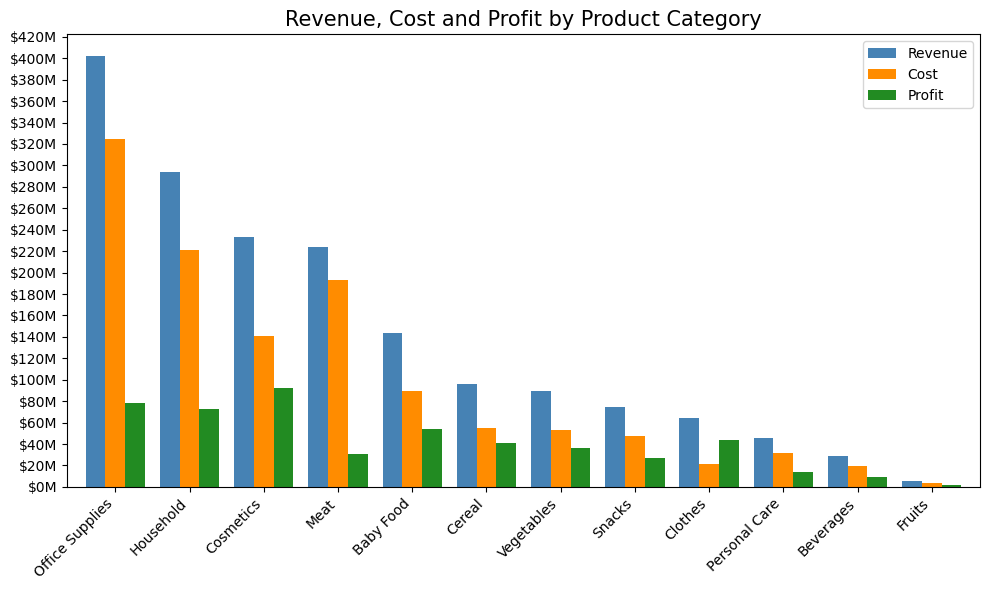

In [ ]:
pivot_finance_by_category_mln = pivot_finance_by_category / 1_000_000
pivot_finance_by_category_mln.plot(kind="bar", figsize=(10, 6), width=0.8, color=["steelblue", "darkorange", "forestgreen"])
plt.title("Revenue, Cost and Profit by Product Category", fontsize=15)
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45, ha='right')
plt.legend(["Revenue", "Cost", "Profit"])
plt.yticks(np.arange(0, pivot_finance_by_category_mln["total_revenue"].max() + 20, 20))
ticks = plt.gca().get_yticks()
plt.gca().set_yticks(ticks)
plt.gca().set_yticklabels([f"${tick:g}M" for tick in ticks])
plt.tight_layout()
plt.show()

На стовпчастій діаграмі відображено категорії товарів за рівнем доходів, витрат та прибутків. Найбільший дохід має категорія товарів Office Supplies (понад 400 млн дол.), проте вони також супроводжуються найвищими витратами (понад 320 млн дол.). Схожа ситуація з Household - високі доходи (близько 300 млн дол.), але і великі витрати (понад 220 млн дол.). Топ третя категорія за доходами є Cosmetics, до того ж вона є найприбутковішою і принесла понад 90 млн дол. чистого прибутку завдяки помірним витратам. Водночас категорія Meat демонструє навпаки низьку прибутковість, оскільки значний дохід майже повністю поглинається витратами, залишаючи лише близько 30 млн дол. прибутку. На противагу цьому, Clothes має понад 40 млн дол. прибутку при відносно невеликому загальному доході та мінімальних витратах. Категорія Fruits має найменші фінансові показники, проте все ж її прибутки сягають понад 1 млн дол.

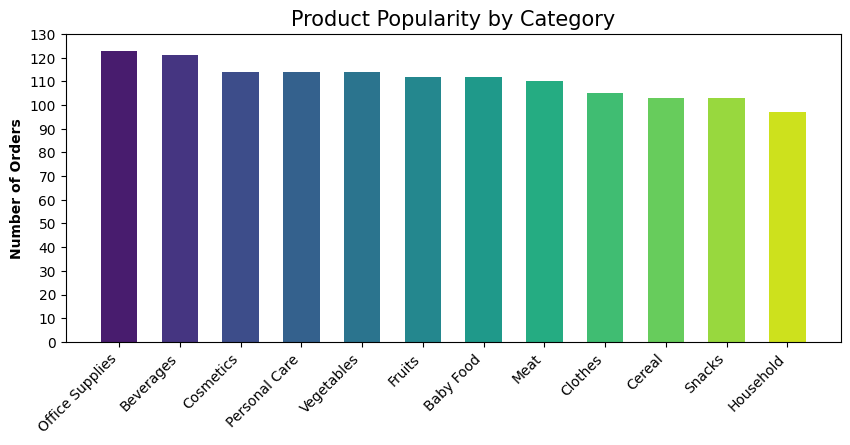

In [ ]:
colors = sns.color_palette("viridis", len(pivot_orders_by_category))

plt.figure(figsize=(10, 4))
plt.bar(pivot_orders_by_category.index, pivot_orders_by_category.values.flatten(), color=colors, width=0.6)
plt.title("Product Popularity by Category", fontsize=15)
plt.xlabel("")
plt.ylabel("Number of Orders", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.yticks(np.arange(0, pivot_orders_by_category["order_id"].max() + 10, 10))
plt.show()

 На стовпчастій діаграмі відображено категорії товарів за рівнем їх популярності. Лідером є Office Supplies та Beverages із показником понад 120 замовлень. Більшість категорій, зокрема Cosmetics, Personal Care, Vegetables та Fruits мають приблизно від 110 до 115 замовлень. Найменш популярними за кількістю замовлень виявилися Cereal, Snacks, а також Household, яка є єдиною на графіку, що не подолала позначку в 100 замовлень.

In [ ]:
pivot_finance_by_country = pd.pivot_table(df, values=["total_revenue", "total_cost", "total_profit"], index=["country_name"], aggfunc="sum")
pivot_finance_by_country = pivot_finance_by_country[["total_revenue", "total_cost", "total_profit"]]
pivot_finance_by_country = pivot_finance_by_country.sort_values(by="total_revenue", ascending=False)
pivot_finance_by_country.style.format("${:,.2f}")

,total_revenue,total_cost,total_profit
country_name,,,
Unknown,"$103,145,646.95","$75,420,223.01","$27,725,423.94"
Czech Republic,"$53,543,932.14","$39,908,338.36","$13,635,593.78"
Ukraine,"$53,252,317.54","$38,447,391.80","$14,804,925.74"
Bosnia and Herzegovina,"$50,117,508.49","$36,859,905.72","$13,257,602.77"
Macedonia,"$49,222,085.25","$35,537,985.30","$13,684,099.95"
San Marino,"$47,883,708.48","$34,090,715.67","$13,792,992.81"
Andorra,"$47,756,693.17","$32,346,656.54","$15,410,036.63"
Portugal,"$47,172,189.84","$35,826,782.25","$11,345,407.59"
Malta,"$47,145,320.81","$32,535,192.93","$14,610,127.88"


In [ ]:
pivot_orders_by_country = pd.pivot_table(df, values=["order_id"], index=["country_name"], aggfunc="count")
pivot_orders_by_country = pivot_orders_by_country.sort_values(by="order_id", ascending=False)
pivot_orders_by_country

,order_id
country_name,
Unknown,82
Andorra,40
San Marino,40
Romania,34
Ukraine,33
Bosnia and Herzegovina,33
Russia,32
Macedonia,32
Malta,32


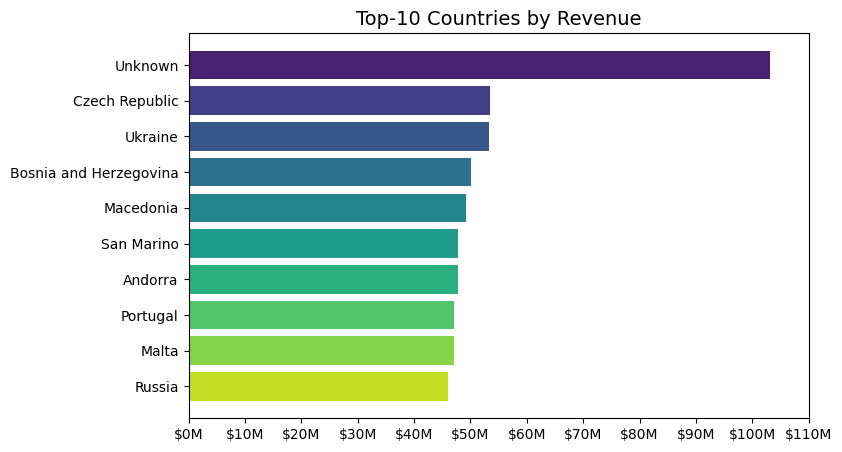

In [ ]:
country_finance_metrics = df.groupby("country_name")[["total_revenue", "total_cost", "total_profit"]].sum()

top_10_revenue_country = country_finance_metrics.sort_values(by="total_revenue", ascending=False).head(10) / 1_000_000
top_10_revenue_country = top_10_revenue_country.iloc[::-1]

colors = sns.color_palette("viridis_r", len(top_10_revenue_country))

plt.figure(figsize=(8, 5))
plt.barh(top_10_revenue_country.index, top_10_revenue_country["total_revenue"], color=colors)
plt.title("Top-10 Countries by Revenue", fontsize=14)
plt.xlabel("")
plt.xticks(np.arange(0, top_10_revenue_country["total_revenue"].max() + 10, 10))
ticks = plt.gca().get_xticks()
plt.gca().set_xticks(ticks)
plt.gca().set_xticklabels([f"${tick:g}M" for tick in ticks])
plt.show()

 На горизонтальній стовпчастій діаграмі відображено топ-10 країн за рівнем доходів. Абсолютним лідером із великим відривом є невизначена група країн (Unknown) з понад 100 млн дол. доходу. Наступними йдуть Czech Republic та Ukraine, показники яких майже однакові та трохи перевищують позначку у 50 млн дол. Більшість інших країн, зокрема Bosnia and Herzegovina, Macedonia, San Marino, Andorra, Portugal та Malta формують групу з доходом трохи менше 50 млн дол. кожна. Замикає топ-10 Russia з найнижчим показником серед представлених країн, який становить близько 45 млн дол.

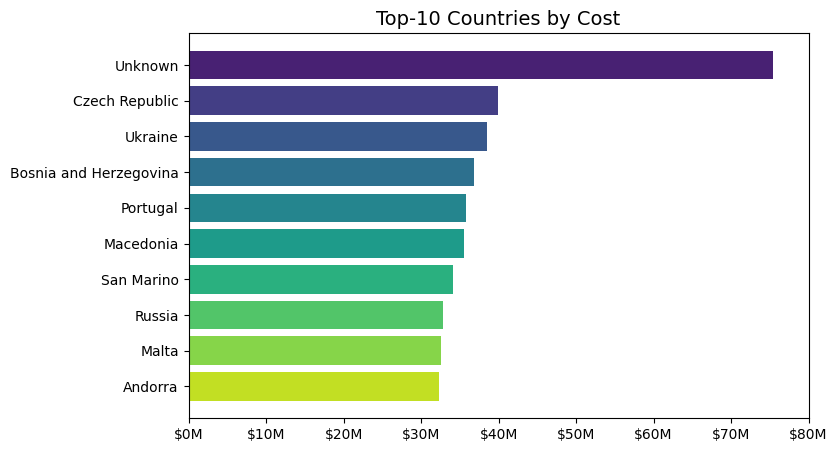

In [ ]:
top_10_cost_country = country_finance_metrics.sort_values(by="total_cost", ascending=False).head(10) / 1_000_000
top_10_cost_country = top_10_cost_country.iloc[::-1]

colors = sns.color_palette("viridis_r", len(top_10_cost_country))

plt.figure(figsize=(8, 5))
plt.barh(top_10_cost_country.index, top_10_cost_country["total_cost"], color=colors)
plt.title("Top-10 Countries by Cost", fontsize=14)
plt.xlabel("")
ticks = plt.gca().get_xticks()
plt.gca().set_xticks(ticks)
plt.gca().set_xticklabels([f"${tick:g}M" for tick in ticks])
plt.show()

 На горизонтальній стовпчастій діаграмі відображено топ-10 країн за рівнем витрат. Лідером є категорія Unknown, витрати якої значно перевищують інші та сягають приблизно 75 млн дол. Друге місце з майже вдвічі меншим показником (близько 40 млн дол.) посідає Czech Republic, за нею Ukraine із витратами близько 38 млн дол. Країни Bosnia and Herzegovina, Portugal та Macedonia демонструють поступове зниження показників від 37 до 35 млн дол. Замикають десятку лідерів за витратами San Marino, Russia, Malta та Andorra, які формують групу з найнижчими показниками на графіку, що коливаються у діапазоні від 32 до 34 млн дол.

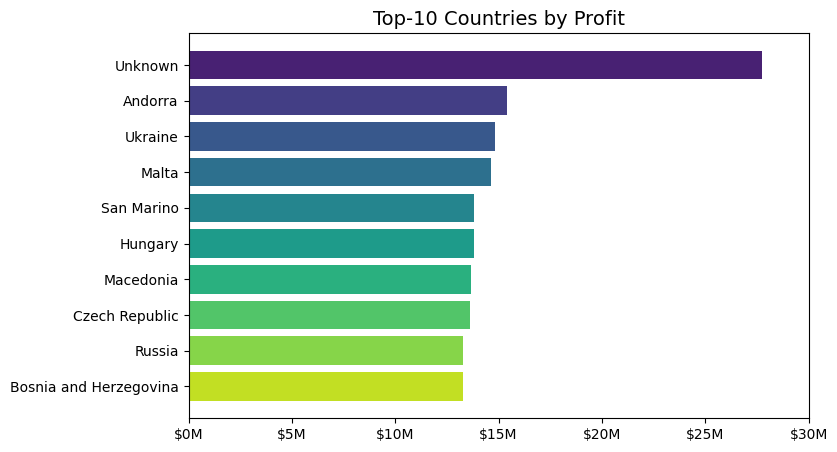

In [ ]:
top_10_profit_country = country_finance_metrics.sort_values(by="total_profit", ascending=False).head(10) / 1_000_000
top_10_profit_country = top_10_profit_country.iloc[::-1]

colors = sns.color_palette("viridis_r", len(top_10_cost_country))

plt.figure(figsize=(8, 5))
plt.barh(top_10_profit_country.index, top_10_profit_country["total_profit"], color=colors)
plt.title("Top-10 Countries by Profit", fontsize=14)
plt.xlabel("")
ticks = plt.gca().get_xticks()
plt.gca().set_xticks(ticks)
plt.gca().set_xticklabels([f"${tick:g}M" for tick in ticks])
plt.show()

На горизонтальній стовпчастій діаграмі відображено топ-10 країн за рівнем прибутків. Лідером залишається категорія Unknown, прибуток якої близько 28 млн дол. На другому місці Andorra з показником трохи більше ніж 15 млн дол. Трійку замикає Ukraine із прибутком близько 15 млн дол., за якою слідує Malta (близько 14,5 млн дол.). Решта країн - San Marino, Hungary, Macedonia, Czech Republic, russia та Bosnia and Herzegovina формують групу з показниками прибутку у діапазоні від 13 до 14 млн дол.

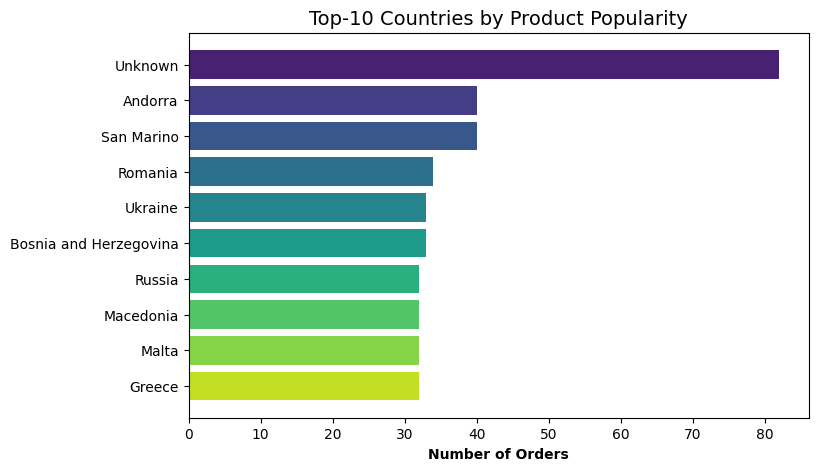

In [ ]:
top_10_orders_by_country = pivot_orders_by_country.head(10)
top_10_orders_by_country = top_10_orders_by_country.iloc[::-1]

colors = sns.color_palette("viridis_r", len(top_10_orders_by_country))

plt.figure(figsize=(8, 5))
plt.barh(top_10_orders_by_country.index, top_10_orders_by_country.values.flatten(), color=colors)
plt.title("Top-10 Countries by Product Popularity", fontsize=14)
plt.xlabel("Number of Orders", fontweight='bold')
plt.show()

На горизонтальній стовпчастій діаграмі відображено топ-10 країн за рівнем замовлень. Як і на попередніх графіках, абсолютним лідером є категорія Unknown з понад 80 замовлень. Другу та третю позиції займають Andorra та San Marino, кожна з яких має рівно по 40 замовлень. Далі у рейтингу йде Romania з показником близько 34 замовлень, за якою йде Ukraine та Bosnia and Herzegovina (приблизно 33 замовлення). Замикають десятку лідерів Russia, Macedonia, Malta та Greece, які мають по 32 замовлення кожна.   

In [ ]:
pivot_finance_by_region = pd.pivot_table(df, values=["total_revenue", "total_cost", "total_profit"], index=["region"], aggfunc="sum")
pivot_finance_by_region = pivot_finance_by_region[["total_revenue", "total_cost", "total_profit"]]
pivot_finance_by_region = pivot_finance_by_region.sort_values(by="total_revenue", ascending=False)
pivot_finance_by_region.style.format("${:,.2f}")

,total_revenue,total_cost,total_profit
region,,,
Europe,"$1,505,652,873.89","$1,057,096,091.78","$448,556,782.11"
Unknown,"$103,145,646.95","$75,420,223.01","$27,725,423.94"
Asia,"$93,330,887.37","$68,178,634.42","$25,152,252.95"


In [ ]:
pivot_orders_by_region = pd.pivot_table(df, values=["order_id"], index=["region"], aggfunc="count")
pivot_orders_by_region = pivot_orders_by_region.sort_values(by="order_id", ascending=False)
pivot_orders_by_region

,order_id
region,
Europe,1164
Asia,82
Unknown,82


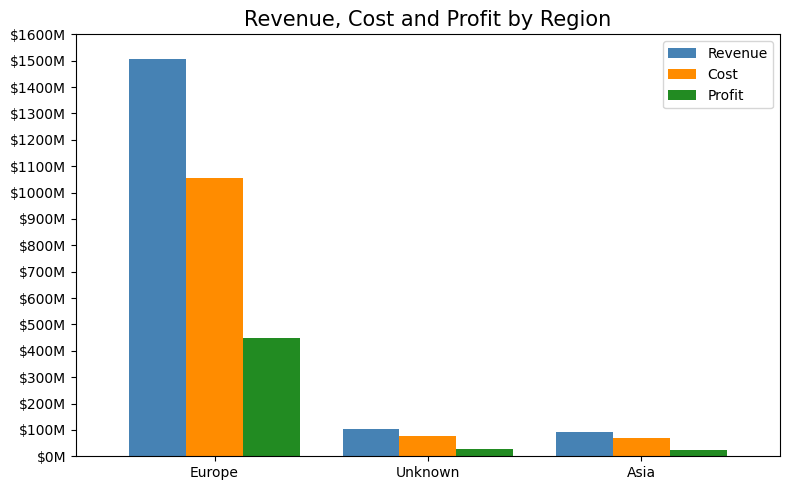

In [ ]:
pivot_finance_by_region_mln = pivot_finance_by_region / 1_000_000
pivot_finance_by_region_mln.plot(kind="bar", figsize=(8, 5), width=0.8, color=["steelblue", "darkorange", "forestgreen"])
plt.title("Revenue, Cost and Profit by Region", fontsize=15)
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=0)
plt.legend(["Revenue", "Cost", "Profit"])
plt.yticks(np.arange(0, pivot_finance_by_region_mln["total_revenue"].max() + 100, 100))
ticks = plt.gca().get_yticks()
plt.gca().set_yticks(ticks)
plt.gca().set_yticklabels([f"${tick:g}M" for tick in ticks])
plt.tight_layout()
plt.show()

На стовпчастій діаграмі відображено регіони за рівнем доходів, витрат, прибутків. Лідером є Europe, дохід якої становить близько 1,500 млн дол., витрати перевищують 1,000 млн дол., а чистий прибуток сягає майже 450 млн дол. Регіон Unknown та Asia, демонструють набагато менші результати, дохід обох цих регіонів близько 100 млн дол., причому Unknown має невеличку перевагу над Asia за всіма трьома показниками.

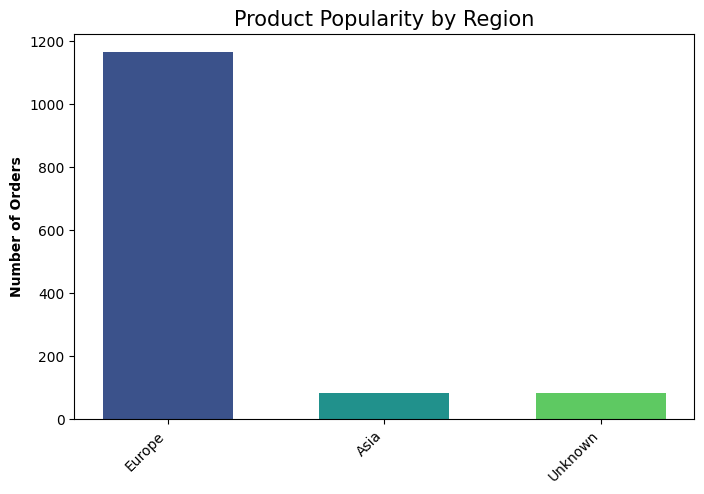

In [ ]:
colors = sns.color_palette("viridis", len(pivot_orders_by_region))

plt.figure(figsize=(8, 5))
plt.bar(pivot_orders_by_region.index, pivot_orders_by_region.values.flatten(), color=colors, width=0.6)
plt.title("Product Popularity by Region", fontsize=15)
plt.xlabel("")
plt.ylabel("Number of Orders", fontweight='bold')
plt.xticks(rotation=45, ha='right')
plt.show()

 На стовпчастій діаграмі відображено регіони за рівнем загальної кількості замовлень. Лідером є Europe з майже 1200 замовлень, натомість показники Asia та категорії Unknown мають менше ніж 100 замовлень.

In [ ]:
pivot_finance_by_channel = pd.pivot_table(df, values=["total_revenue", "total_cost", "total_profit"], index=["sales_channel"], aggfunc="sum")
pivot_finance_by_channel = pivot_finance_by_channel[["total_revenue", "total_cost", "total_profit"]]
pivot_finance_by_channel = pivot_finance_by_channel.sort_values(by="total_revenue", ascending=False)
pivot_finance_by_channel.style.format("${:,.2f}")

,total_revenue,total_cost,total_profit
sales_channel,,,
Offline,"$871,760,623.88","$618,294,105.07","$253,466,518.81"
Online,"$830,368,784.33","$582,400,844.14","$247,967,940.19"


In [ ]:
pivot_orders_by_channel = pd.pivot_table(df, values=["order_id"], index=["sales_channel"], aggfunc="count")
pivot_orders_by_channel = pivot_orders_by_channel.sort_values(by="order_id", ascending=False)
pivot_orders_by_channel

,order_id
sales_channel,
Offline,665
Online,663


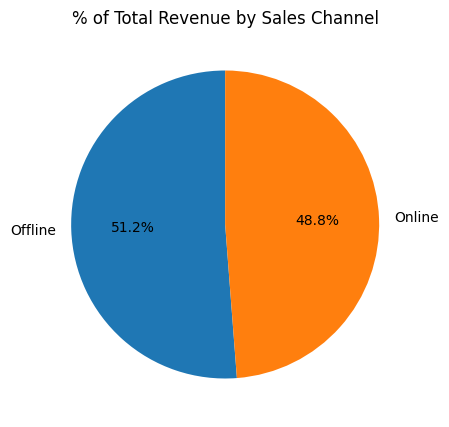

In [ ]:
revenue_by_channel = pivot_finance_by_channel["total_revenue"]
revenue_by_channel.plot(kind="pie", figsize=(8, 5), autopct='%1.1f%%', startangle=90)
plt.title("% of Total Revenue by Sales Channel")
plt.ylabel("")
plt.show()

Кругова діаграма ілюструє відсотковий розподіл загального доходу за каналами продажу. На офлайн-продажі  припадає 51,2% усього доходу, тоді як онлайн-продажі припадає 48,8%. Тобто обидва канали відіграють майже однаково роль у формуванні загального доходу.

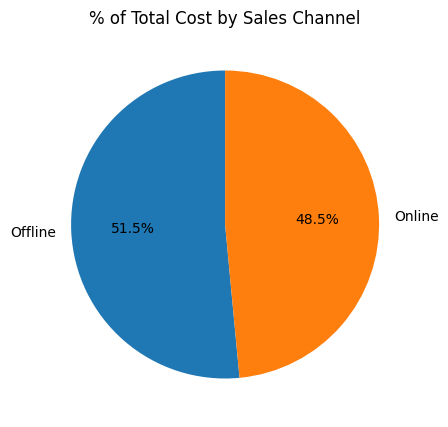

In [ ]:
cost_by_channel = pivot_finance_by_channel["total_cost"]
cost_by_channel.plot(kind="pie", figsize=(8, 5), autopct='%1.1f%%', startangle=90)
plt.title("% of Total Cost by Sales Channel")
plt.ylabel("")
plt.show()

Кругова діаграма ілюструє відсотковий розподіл загальних витрат за каналами продажу. На офлайн-продажі  припадає 51,5% усіх витрат, тоді як онлайн-продажі припадає 48,5%. Тобто витрати майже однакові, проте офлайн вимагає трохи більше ніж онлайн.

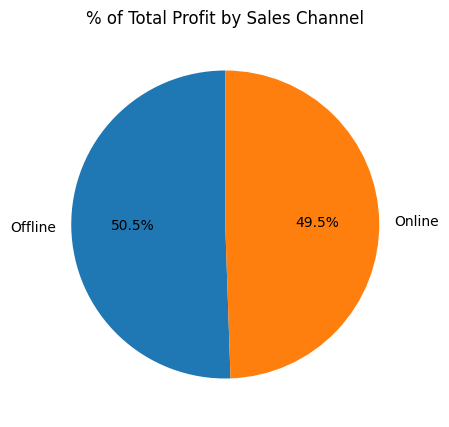

In [ ]:
profit_by_channel = pivot_finance_by_channel["total_profit"]
profit_by_channel.plot(kind="pie", figsize=(8, 5), autopct='%1.1f%%', startangle=90)
plt.title("% of Total Profit by Sales Channel")
plt.ylabel("")
plt.show()

Кругова діаграма ілюструє відсотковий розподіл загальних прибутків за каналами продажу. На офлайн-продажі  припадає 50,5% усього прибутку, тоді як онлайн-продажі припадає 49,5%. Тобто обидва канали відіграють майже однаково роль у формуванні загального прибутку.

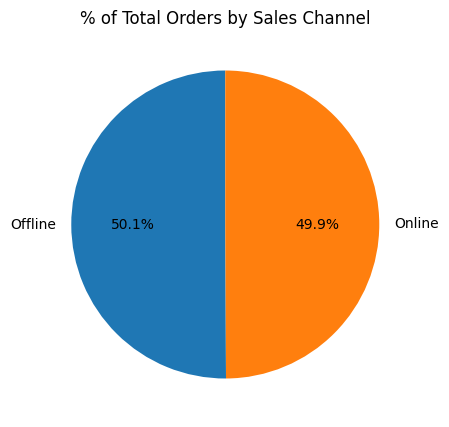

In [ ]:
orders_by_channel = pivot_orders_by_channel["order_id"]
orders_by_channel.plot(kind="pie", figsize=(8, 5), autopct='%1.1f%%', startangle=90)
plt.title("% of Total Orders by Sales Channel")
plt.ylabel("")
plt.show()

Кругова діаграма ілюструє відсотковий розподіл загальних замовлень за каналами продажу. На офлайн-продажі припадає 50,1% усіх замовлень, тоді як на онлайн-продажі 49,9%. Тобто обидва канали відіграють майже однакову роль у формуванні загального обсягу замовлень компанії.

### Аналіз інтервалів часу між замовленням та його відвантаженням в розрізі категорій товарів, країн, регіонів.

In [ ]:
df["interval (days)"] = (df["ship_date"] - df["order_date"]).dt.days

In [ ]:
print(f"Максимальна тривалість днів між замовленням та його відвантаженням: {df["interval (days)"].max()} днів")

Максимальна тривалість днів між замовленням та його відвантаженням: 50 днів


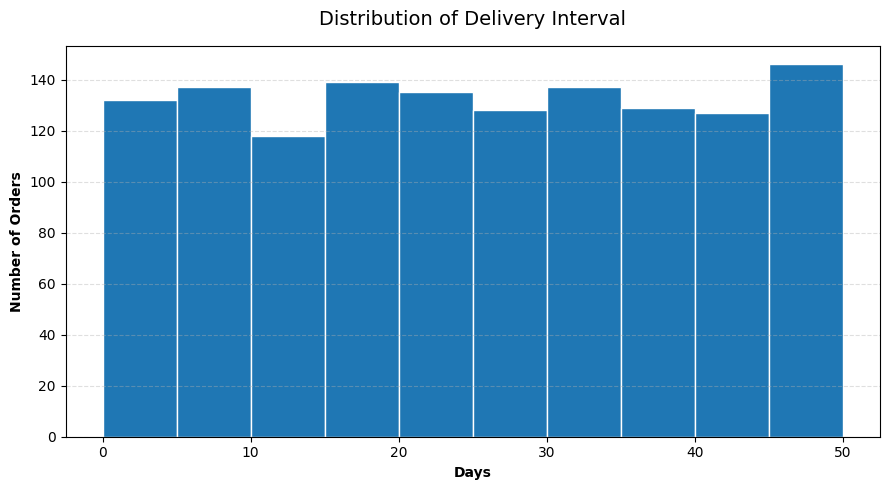

In [ ]:
plt.figure(figsize=(9, 5))
plt.hist(df["interval (days)"], bins=10, edgecolor="white")
plt.title("Distribution of Delivery Interval", fontsize=14, pad=15)
plt.xlabel("Days", fontweight="bold")
plt.ylabel("Number of Orders", fontweight="bold")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

Гістограма відображає кількість замовлень залежно від терміну їх виконання у днях. Кількість замовлень у кожному 5-денному інтервалі стабільно тримається у діапазоні від 115 до 145. Найвищий показник (понад 140 замовлень) припадає на найдовший інтервал від 45 до 50 днів, тоді як найменше замовлень виконується в проміжку від 10 до 15 дн.

In [ ]:
median_interval_by_category = df.groupby("item_type")["interval (days)"].median()
median_interval_by_category.sort_values(ascending=False)

,interval (days)
item_type,
Cereal,29.0
Baby Food,28.5
Cosmetics,28.0
Office Supplies,27.0
Snacks,25.0
Meat,25.0
Household,24.0
Beverages,23.0
Fruits,23.0


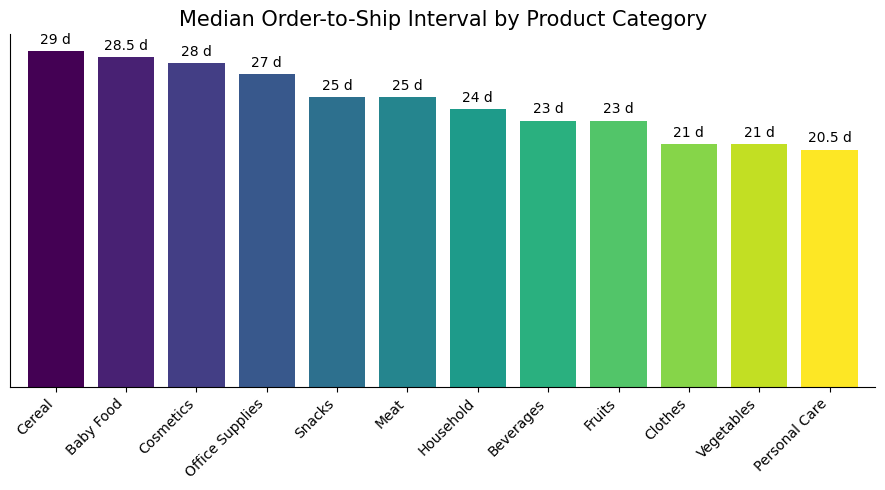

In [ ]:
colors = plt.cm.viridis(np.linspace(0, 1, len(median_interval_by_category.sort_values(ascending=False))))
ax = median_interval_by_category.sort_values(ascending=False).plot(kind="bar", figsize=(9, 5), width=0.8, legend = False, color=colors)
ax.bar_label(ax.containers[0], fmt='%g d', padding=3)
plt.title("Median Order-to-Ship Interval by Product Category", fontsize=15)
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45, ha='right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_yticks([])
plt.tight_layout()
plt.show()

Стовпчаста діаграма демонструє медіанний час у днях між оформленням замовлення та його відвантаженням залежно від категорії товару. Категорії Cereal, Baby Food та Cosmetics мають найдовші медіанні терміни відвантаження, які становлять 29, 28,5 та 28 днів відповідно. Замовлення на Office Supplies обробляються в середньому 27 днів, тоді як Snacks та Meat відвантажуються за 25 днів. Для категорій Household, Beverages та Fruits цей показник становить від 24 до 23 днів. Найменше часу потребує Clothes та Vegetables (по 21 дню), та Personal Care з показником у 20,5 днів.

In [ ]:
interval_analysis_by_country = df.groupby("country_name").agg(total_profit=("total_profit", "sum"), median_days=("interval (days)", "median"))
interval_analysis_by_country["median_days"].sort_values(ascending=False)

,median_days
country_name,
Hungary,36.0
Russia,34.0
Monaco,33.0
Georgia,32.0
Slovakia,32.0
Finland,31.0
Luxembourg,30.5
Lithuania,30.0
Bosnia and Herzegovina,30.0


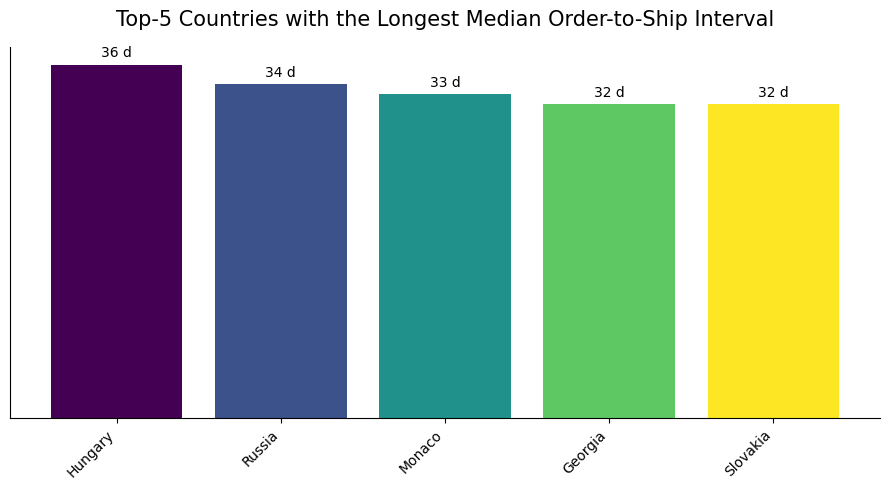

In [ ]:
longest_top_interval_by_country = interval_analysis_by_country["median_days"].sort_values(ascending=False).head(5)

colors = plt.cm.viridis(np.linspace(0, 1, len(longest_top_interval_by_country)))

ax = longest_top_interval_by_country.plot(kind="bar", figsize=(9, 5), width=0.8, legend = False, color=colors)
ax.bar_label(ax.containers[0], fmt='%g d', padding=3)
plt.title("Top-5 Countries with the Longest Median Order-to-Ship Interval", fontsize=15, pad=15)
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45, ha='right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_yticks([])
plt.tight_layout()
plt.show()

На стовпчиковій діаграмі демонструються топ-5 країн із найдовшим інтервалом часу між замовленням та відвантаженням. Найдовшим є для Hungary - медіана 36 днів, для Russia - медіана 34 дні та для Monaco - медіана 33 дні.

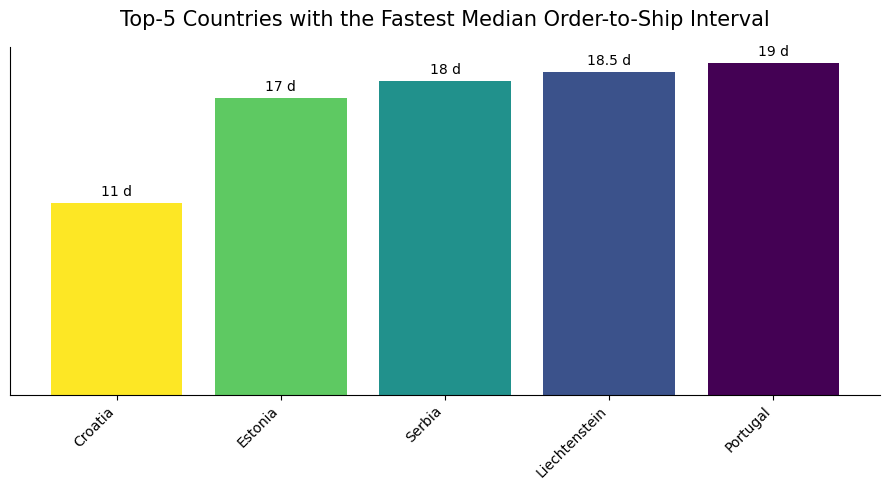

In [ ]:
fastest_top_interval_by_country = interval_analysis_by_country["median_days"].sort_values().head(5)

colors = plt.cm.viridis(np.linspace(1, 0, len(fastest_top_interval_by_country)))

ax = fastest_top_interval_by_country.plot(kind="bar", figsize=(9, 5), width=0.8, legend = False, color=colors)
ax.bar_label(ax.containers[0], fmt='%g d', padding=3)
plt.title("Top-5 Countries with the Fastest Median Order-to-Ship Interval", fontsize=15, pad=15)
plt.xlabel("")
plt.ylabel("")
plt.xticks(rotation=45, ha='right')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_yticks([])
plt.tight_layout()
plt.show()

На стовпчиковій діаграмі демонструються топ-5 країн із найшвидшим інтервалом часу між замовленням та відвантаженням. Найшвидшим є для Croatia - медіана 11 днів, для Estonia - медіана 17 дні та для Serbia - медіана 18 дні.

In [ ]:
median_interval_by_region = df.groupby("region")["interval (days)"].median()
median_interval_by_region.sort_values(ascending=False)

,interval (days)
region,
Asia,25.5
Europe,25.0
Unknown,23.5


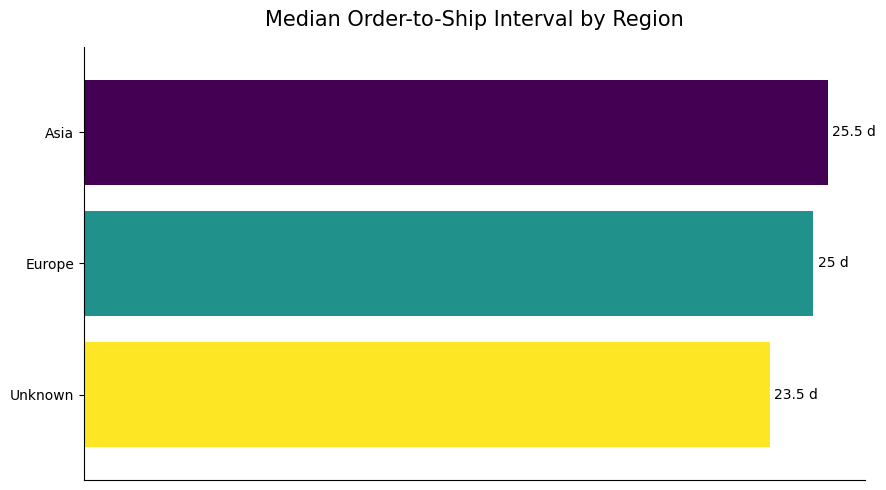

In [ ]:
colors = plt.cm.viridis(np.linspace(1, 0, len(median_interval_by_region.sort_values(ascending=True))))

ax = median_interval_by_region.sort_values(ascending=True).plot(kind="barh", figsize=(9, 5), width=0.8, legend=False, color=colors)

ax.bar_label(ax.containers[0], fmt='%g d', padding=3)
plt.title("Median Order-to-Ship Interval by Region", fontsize=15, pad=15)
plt.xlabel("")
plt.ylabel("")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_xticks([])

plt.tight_layout()
plt.show()

Найбільше часу на відвантаження товару йде в Asia - медіана 25,5 дн., Europe - медіана 25 дн., категорія Unknown - медіана 23,5 дні.

### Аналіз залежності прибутку від часу, необхідного на відвантаження товару

In [ ]:
interval_analysis_by_country = df.groupby("country_name").agg(total_profit=("total_profit", "sum"), median_days=("interval (days)", "median"))
interval_analysis_by_country.sort_values(by="total_profit", ascending=False).style.format({"total_profit": "${:,.2f}"})

,total_profit,median_days
country_name,,
Unknown,"$27,725,423.94",23.500000
Andorra,"$15,410,036.63",26.000000
Ukraine,"$14,804,925.74",29.000000
Malta,"$14,610,127.88",23.000000
San Marino,"$13,792,992.81",20.500000
Hungary,"$13,786,231.03",36.000000
Macedonia,"$13,684,099.95",19.500000
Czech Republic,"$13,635,593.78",28.000000
Russia,"$13,267,682.64",34.000000


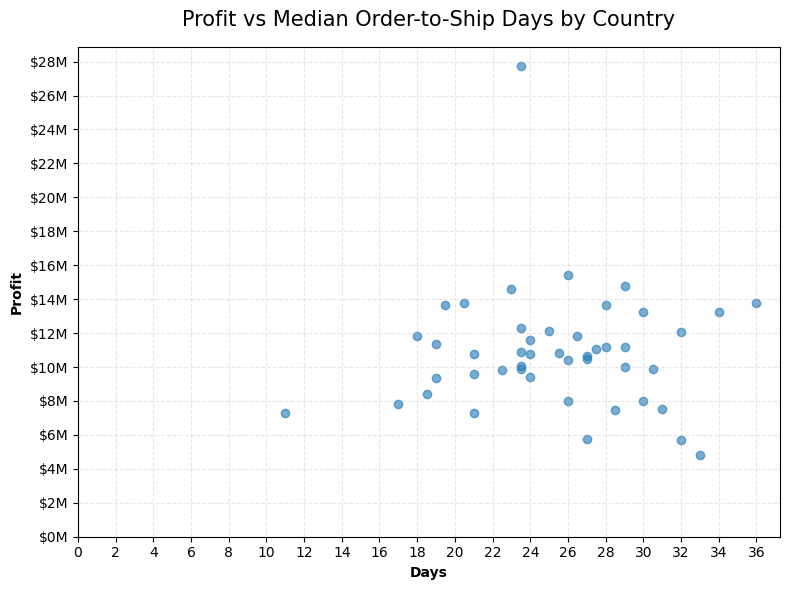

In [ ]:
interval_analysis_by_country["profit_mln"] = interval_analysis_by_country["total_profit"] / 1_000_000

plt.figure(figsize=(8, 6))
plt.scatter(interval_analysis_by_country["median_days"], interval_analysis_by_country["profit_mln"], alpha=0.6)
plt.title("Profit vs Median Order-to-Ship Days by Country", fontsize=15, pad=15)
plt.xlabel("Days", fontweight="bold")
plt.ylabel("Profit", fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.3)
plt.xticks(np.arange(0, interval_analysis_by_country["median_days"].max() + 2, 2))
plt.yticks(np.arange(0, interval_analysis_by_country["profit_mln"].max() + 2, 2))
ticks = plt.gca().get_yticks()
plt.gca().set_yticks(ticks)
plt.gca().set_yticklabels([f"${tick:g}M" for tick in ticks])
plt.tight_layout()
plt.show()

Значної залежності прибутку від часу, необхідного на відвантаження товару, за медіаною по країнах не виявлено. Країни зі схожим рівнем прибутку мають доставку як за 18, так і за 32 дні.

### Аналіз динаміки продажів (у часі) у розрізі категорій товарів, країн, регіонів

In [ ]:
top_5_products_by_revenue = df.groupby("item_type")["total_revenue"].sum().sort_values(ascending=False).head(5)

In [ ]:
df_top_5_products_by_revenue=df[df["item_type"].isin(top_5_products_by_revenue.index)].copy()

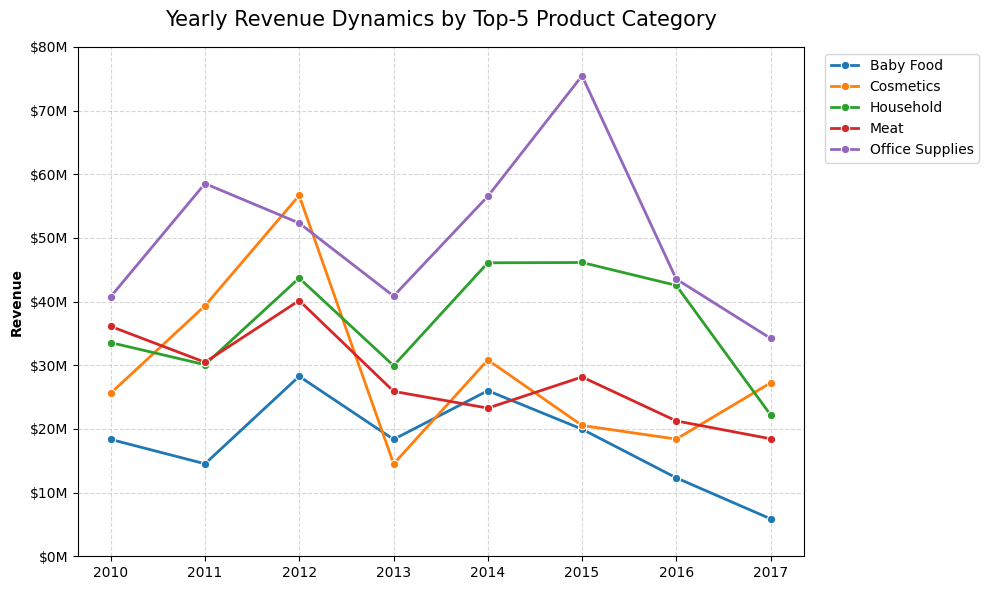

In [ ]:
df_top_5_products_by_revenue["year"] = df_top_5_products_by_revenue["order_date"].dt.to_period("Y").dt.to_timestamp()
yearly_by_food_category = df_top_5_products_by_revenue.pivot_table(index="year", columns="item_type", values="total_revenue", aggfunc="sum") / 1_000_000

plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly_by_food_category, dashes=False, linewidth=2, marker="o")
plt.title("Yearly Revenue Dynamics by Top-5 Product Category", fontsize=15, pad=15)
plt.xlabel("")
plt.ylabel("Revenue", fontweight="bold")
plt.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
ticks = plt.gca().get_yticks()
plt.gca().set_yticks(ticks)
plt.gca().set_yticklabels([f"${tick:g}M" for tick in ticks])
plt.tight_layout()
plt.show()

Категорії які візуалізовні на графіку є топ-5 по доходам у компанії. Категорія Office Supplies має найбільший дохід - близько 75 млн дол. у 2015 році. Проте одразу після цього піку спостерігається стрімке падіння до рівня близько 34 млн дол. у 2017 році. Категорія Cosmetics теж має різкий пік доходу у 2012 році (майже до 57 млн дол.), але вже у 2013 році її показники обвалилися до найнижчого для неї рівня — близько 14 млн дол. У 2013 році видно одночасне просідання доходів для більшості топових категорій, особливо для Office Supplies, Cosmetics та Meat. У 2017 році всі категорії (крім Cosmetics) показали теж зниження показнику доходу. Категорія Baby Food у 2017 році має найнижчі позначки на всьому графіку - менше 10 млн дол. Товари групи Household, які трималися більш-менш стабільно у 2014–2015 роках (близько 46 млн дол.), також різко впали до рівня ~22 млн дол. у 2017 році. Це може свідчити про глобальну економічну кризу або внутрішні проблеми компанії в цей період.

In [ ]:
top_5_country_by_revenue = df.groupby("country_name")["total_revenue"].sum().sort_values(ascending=False).head(5)

In [ ]:
df_top_5_country_by_revenue=df[df["country_name"].isin(top_5_country_by_revenue.index)].copy()

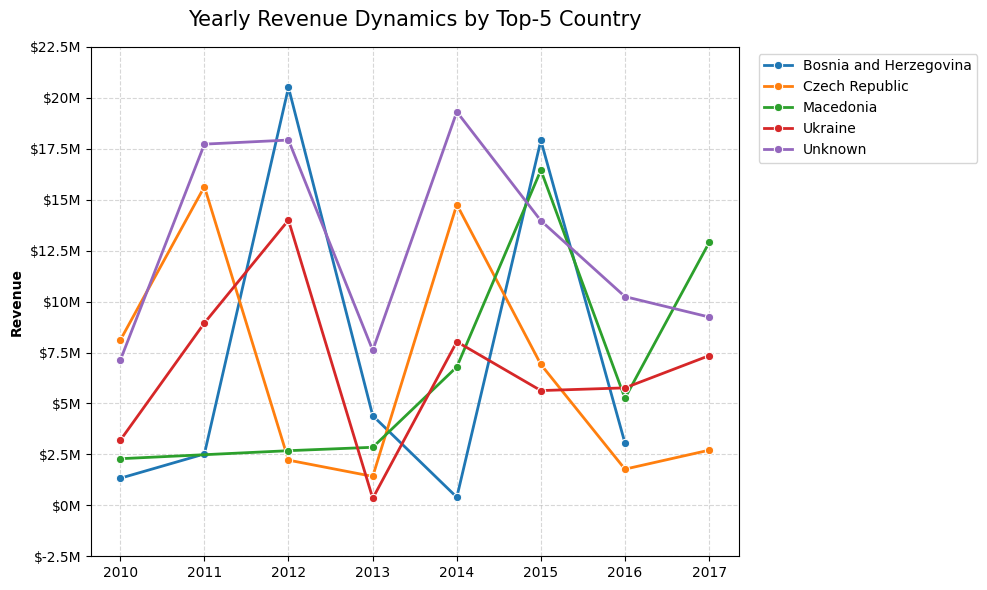

In [ ]:
df_top_5_country_by_revenue["year"] = df_top_5_country_by_revenue["order_date"].dt.to_period("Y").dt.to_timestamp()
yearly_by_country = df_top_5_country_by_revenue.pivot_table(index="year", columns="country_name", values="total_revenue", aggfunc="sum") / 1_000_000

plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly_by_country, dashes=False, linewidth=2, marker="o")
plt.title("Yearly Revenue Dynamics by Top-5 Country", fontsize=15, pad=15)
plt.xlabel("")
plt.ylabel("Revenue", fontweight="bold")
plt.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
ticks = plt.gca().get_yticks()
plt.gca().set_yticks(ticks)
plt.gca().set_yticklabels([f"${tick:g}M" for tick in ticks])
plt.tight_layout()
plt.show()

Країни які візуалізовні на графіку є топ-5 по доходам у компанії. Їхня загальна динаміка є вкрай нестабільною і характеризується екстремальними багатомільйонними стрибками та падіннями. У Bosnia and Herzegovina дохід злетів до понад 20 млн дол. у 2012 році, обвалився практично до 1 млн дол. у 2014 році, тоді знову різко піднявся майже до 18 млн дол. у 2015-му і стрімко впав у 2016-му. Czech Republic	також має хвилеподібні коливання з піками близько 15–16 млн дол. доходу у 2011 та 2014 роках, тоді як Macedonia досягла свого максимуму у понад 16 млн дол. у 2015 році. У 2013 році чітко простежується синхронний обвал доходів, бачимо, що показники Ukraine впали майже до найнижчої позначки на графіку (близько 1 млн дол.), а також ріко просіли показники доходу і у Czech Republic та Bosnia and Herzegovina, що може вказувати на регіональну кризу. Водночас категорія без визначеної країни "Unknown" досягає піку майже у 19–20 млн дол. у 2014 році. Наприкінці аналізованого періоду, у 2017 році Macedonia та Ukraine демонструють впевнене зростання, натомість показники Czech Republic залишаються на низькому рівні (близько 2.5 млн дол.), а лінія Bosnia and Herzegovina обривається у 2016 році, що може свідчити про повну зупинку продажів у цій країні.

In [ ]:
df["year"] = df["order_date"].dt.to_period("Y").dt.to_timestamp()

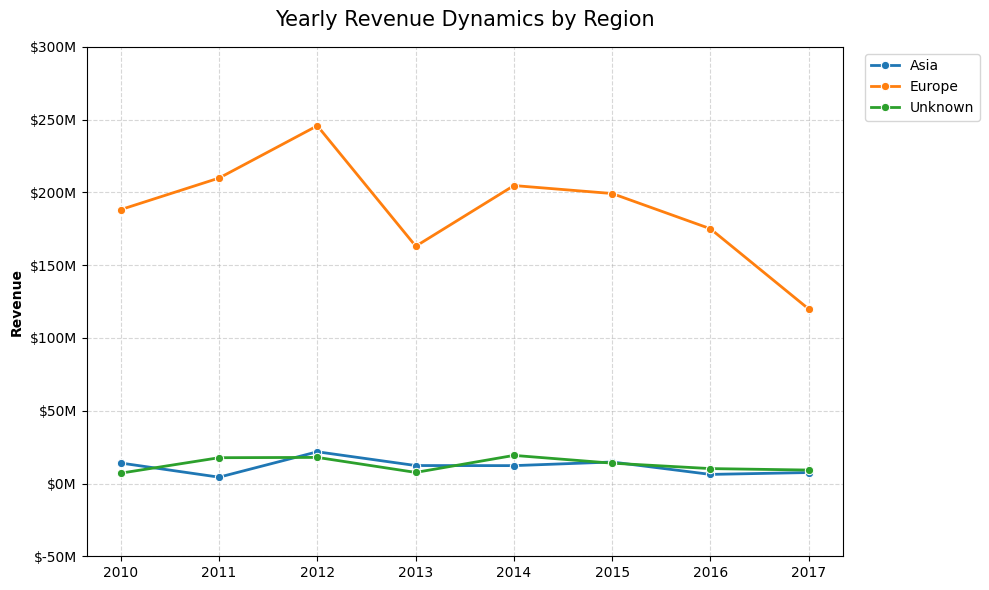

In [ ]:
yearly_by_region = df.pivot_table(index="year", columns="region", values="total_revenue", aggfunc="sum") / 1_000_000
plt.figure(figsize=(10, 6))
sns.lineplot(data=yearly_by_region, dashes=False, linewidth=2, marker="o")
plt.title("Yearly Revenue Dynamics by Region", fontsize=15, pad=15)
plt.xlabel("")
plt.ylabel("Revenue", fontweight="bold")
plt.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
ticks = plt.gca().get_yticks()
plt.gca().set_yticks(ticks)
plt.gca().set_yticklabels([f"${tick:g}M" for tick in ticks])
plt.tight_layout()
plt.show()

Europe є абсолютним лідером за доходами компанії, досягнувши піку у майже 250 млн дол. у 2012 році. На європейському ринку найяскравіше відображається криза 2013 року, коли дохід стрімко обвалився приблизно до 160 млн дол., а також простежується чіткий негативний тренд останніх років, що призвів до падіння доходів до рівня 120 млн дол. у 2017 році. Доходи в регіоні Asia впродовж усього періоду помітно менші порівняно з Europe, не демонструють ознак зростання і жодного разу не перетнули позначку в 25 млн дол. Доходи в категорії "Unknown" стабільно тримаються у спільному діапазоні з Asia (10–25 млн дол.), що може свідчити про ймовірність того, що ця невизначена категорія насправді належить до регіону Asia.

 ### Аналіз продажів товарів за днями тижня

In [ ]:
df["day_of_week"] = df["order_date"].dt.day_name()
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["day_of_week"] = pd.Categorical(df["day_of_week"], categories=days_order, ordered=True)

In [ ]:
sales_by_days = df.pivot_table(index="item_type", columns="day_of_week", values="total_revenue", aggfunc="sum", observed=False)

percent_sales_by_days = sales_by_days.div(sales_by_days.sum(axis=1), axis=0) * 100
percent_sales_by_days.round(1)

day_of_week,Monday,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
item_type,,,,,,,
Baby Food,10.9,15.2,14.4,13.1,14.1,15.7,16.7
Beverages,16.7,13.1,12.3,14.0,11.0,16.7,16.2
Cereal,8.9,12.5,12.5,12.5,13.5,20.7,19.4
Clothes,11.5,21.0,7.4,14.9,10.4,17.1,17.8
Cosmetics,10.5,15.3,12.9,13.2,26.5,12.2,9.4
Fruits,20.0,7.2,14.5,9.5,7.4,18.4,22.9
Household,24.5,4.7,21.7,10.6,14.8,12.9,10.8
Meat,18.9,16.3,16.8,12.4,10.1,15.0,10.5
Office Supplies,15.2,12.4,15.2,13.0,17.1,10.5,16.6


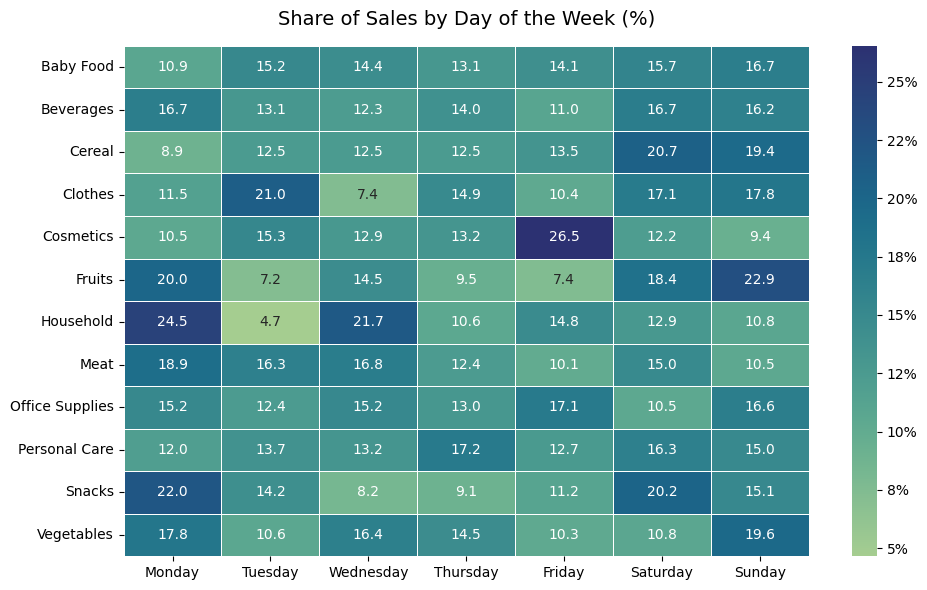

In [ ]:
plt.figure(figsize=(10, 6))
ax = sns.heatmap(percent_sales_by_days, annot=True, fmt=".1f", cmap="crest", linewidths=.5, cbar_kws={'format': '%.0f%%'}  )
plt.title("Share of Sales by Day of the Week (%)", fontsize=14, pad=15)
plt.xlabel("")
plt.ylabel("")

plt.tight_layout()
plt.show()

Теплова карта демонструє частку продажів конкретної категорії товару по днях тижня. Помітно, що у п'ятницю категорія Cosmetics досягає піку продажів у 26.5%, тоді як в інші дні цей показник коливається в межах 9.4%–15.3%. Категорія Household має пік продажів у понеділок (24.5%) та середу (21.7%), проте у вівторок продажі різко падають до 4.7%. Cereal показує чітко виражений пік на вихідних (20.7% у суботу та 19.4% у неділю). Snacks активно розкуповують у суботу (20.2%) та понеділок (22.0%). Fruits досягають свого максимуму в неділю (22.9%) та понеділок (20.0%).  Vegetables найактивніше купують у неділю (19.6%) та понеділок (17.8%). Категорія Clothes показує несподіваний пік у вівторок (21.0%), після чого в середу відбувається різкий спад до 7.4%. Натомість товари Baby Food, Beverages, Meat та Personal Care, Office Supplies розподілені протягом тижня відносно рівномірно, без різких стрибків (в діапазоні 10–18%).

# 4. Reporting
### 1. Головні проблеми та ризики

**1.1. Нестабільність продажів**: дані показують величезні хвилеподібні стрибки у доходах ключових країн. Наприклад, дохід у Bosnia and Herzegovina спочатку різко зростає до понад 20 млн дол., а потім стрімко падає до позначки 2.5 млн дол. Продажі компанії не є регулярними, тому якщо великого замовлення в поточному році немає — дохід країни падає до мінімальних значень.

**1.2. Залежність від одного регіону**: абсолютним лідером за доходами є регіон Europe (пік у ~250 млн дол.). До того ж, топ-5 найприбутковіших країн знаходяться у Східній Європі та на Балканах (Bosnia and Herzegovina, Czech Republic, Macedonia, Ukraine), тому якщо в цьому конкретному регіоні стається криза (як видно на графіках у 2013 та 2017 роках), страждає весь бізнес. Інші регіони, такі як Asia, приносять значно менше (до 25 млн дол.) і не можуть перекрити ці збитки.

**1.3. Проблема "Unknown"**: категорія без визначеної країни (**Unknown**) приносить великі доходи (~6% від загального доходу). За обсягами це майже дорівнює всім продажам у регіоні Asia, тому є висока ймовірність, що насправді невизначені країни належать до регіону Asia, але через помилку системи вони не розпізнаються.

### 2. Логістика та аналіз продажів

**2.1. Швидкість доставки не впливає на прибуток**: аналіз показав, що швидша доставка не приносить більше грошей компанії. Країни, які замовляють найбільше, у середньому чекають на свій товар близько місяця (від 20 до 30 днів). Тому компанії немає сенсу витрачати великі бюджети на прискорену доставку, оскільки це не збільшує продажі.

**2.2. Сезонність**: різні категорії товарів мають виражений чіткий попит у визначені дні тижня. Наприклад, Cosmetics має виражений пік у п'ятницю (26.5% від усіх продажів за тиждень), а Cereal найчастіше купують на вихідних. Household активно купують у понеділок та середу. Інші базові товари продаються рівномірно кожного дня.

### 3. Рекомендації

По-перше, необхідно для якіснішого аналізу покращити збір і валідацію даних про країни, виправити помилку з категорією "Unknown". Перевірити базу даних і знайти, звідки приходять ці замовлення (перевірити гіпотезу, що це продажі в Asia).

По-друге, почати активно розвивати ринок Asia. Це захистить компанію від збитків, оскільки матиме дохід з інших континентів, якщо в Європі знову впадуть продажі.

По-третє, складати графік поставок за днями тижня, наприклад завозити Cosmetics у четвер, а Snacks перед вихідними. Це допоможе уникнути ситуацій, коли в найбільш активний день товар закінчується на полицях.

І останнє, аналіз довів, що швидкість доствки не впливає на прибуток. Відмова від термінових доставок дозволить компанії заощадити великі суми грошей на логістиці.